# Netflix Business Analytics: Auspify Internship | Afry Nizam
**Tasks completed:** 1 (Content Portfolio), 2 (Global Market), 3 (Audience Segmentation), 4 (Growth & Trends)

**Intern:** _<your name>_  |  **Tools:** Python (pandas, matplotlib, seaborn)  |  **Dataset:** `Dataset.csv` (8,790 Netflix titles)

#Auspify #AuspifyTechnologies #AuspifyInternship #AuspifyProjects

In [9]:
import os
import pandas as pd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})
RED, DARK, GREY = "#E50914", "#221f1f", "#b3b3b3"
os.makedirs("charts", exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"charts/{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

## Step 0: Import and prepare the dataset

In [10]:
df = pd.read_csv("Dataset.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (8790, 10)


,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [11]:
print("Missing values per column:")
print(df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Placeholder 'Not Given' in director:", (df["director"] == "Not Given").sum())
print("Placeholder 'Not Given' in country :", (df["country"] == "Not Given").sum())

Missing values per column:
show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Duplicate rows: 0
Placeholder 'Not Given' in director: 2588
Placeholder 'Not Given' in country : 287


In [12]:
# --- Cleaning ---
# 1. Dates stored as text -> real dates
df["date_added"] = pd.to_datetime(df["date_added"])
df["year_added"] = df["date_added"].dt.year

# 2. 'duration' mixes minutes (movies) and seasons (TV) -> split into number + unit
df[["duration_num", "duration_unit"]] = df["duration"].str.extract(r"(\d+)\s*(\w+)")
df["duration_num"] = df["duration_num"].astype(int)

# 3. 'Not Given' is a placeholder, not a real value -> label it Unknown
df["country"] = df["country"].replace("Not Given", "Unknown")
df["director"] = df["director"].replace("Not Given", "Unknown")

print("Latest date_added in data:", df["date_added"].max().date())
print("Release years:", df["release_year"].min(), "to", df["release_year"].max())
df.dtypes

Latest date_added in data: 2021-09-25
Release years: 1925 to 2021


,0
show_id,object
type,object
title,object
director,object
country,object
date_added,datetime64[ns]
release_year,int64
rating,object
duration,object
listed_in,object


**Cleaning notes:** no nulls and no duplicates. I converted `date_added` to a real date, split `duration` into a number and a unit (minutes vs seasons), and relabelled the placeholder "Not Given" as "Unknown" (287 countries, 2,588 directors). Each row holds a single country, so no splitting was needed.

---
# Task 1: Netflix Content Portfolio Analysis
**Goal:** understand the distribution of Movies vs TV Shows.

In [13]:
type_counts = df["type"].value_counts()
mix = pd.DataFrame({"Titles": type_counts, "Share (%)": (type_counts / len(df) * 100).round(1)})
mix

,Titles,Share (%)
type,,
Movie,6126,69.7
TV Show,2664,30.3


In [14]:
movies = df[df["type"] == "Movie"]
shows = df[df["type"] == "TV Show"]
known_countries = df.loc[df["country"] != "Unknown", "country"]

kpis = pd.DataFrame(
    [
        ("Total titles", f"{len(df):,}"),
        ("Movies", f"{len(movies):,} ({len(movies)/len(df):.1%})"),
        ("TV Shows", f"{len(shows):,} ({len(shows)/len(df):.1%})"),
        ("Movies per TV Show", f"{len(movies)/len(shows):.1f}"),
        ("Countries represented", f"{known_countries.nunique()}"),
        ("Unique directors", f"{df.loc[df['director'] != 'Unknown', 'director'].nunique():,}"),
        ("Avg movie length (min)", f"{movies['duration_num'].mean():.1f}"),
        ("Avg seasons per TV Show", f"{shows['duration_num'].mean():.2f}"),
        ("TV Shows with only 1 season", f"{(shows['duration_num'] == 1).mean():.1%}"),
        ("Release year range", f"{df['release_year'].min()} - {df['release_year'].max()}"),
    ],
    columns=["KPI", "Value"],
)
kpis

,KPI,Value
0,Total titles,"8,790"
1,Movies,"6,126 (69.7%)"
2,TV Shows,"2,664 (30.3%)"
3,Movies per TV Show,2.3
4,Countries represented,85
5,Unique directors,"4,527"
6,Avg movie length (min),99.6
7,Avg seasons per TV Show,1.75
8,TV Shows with only 1 season,67.2%
9,Release year range,1925 - 2021


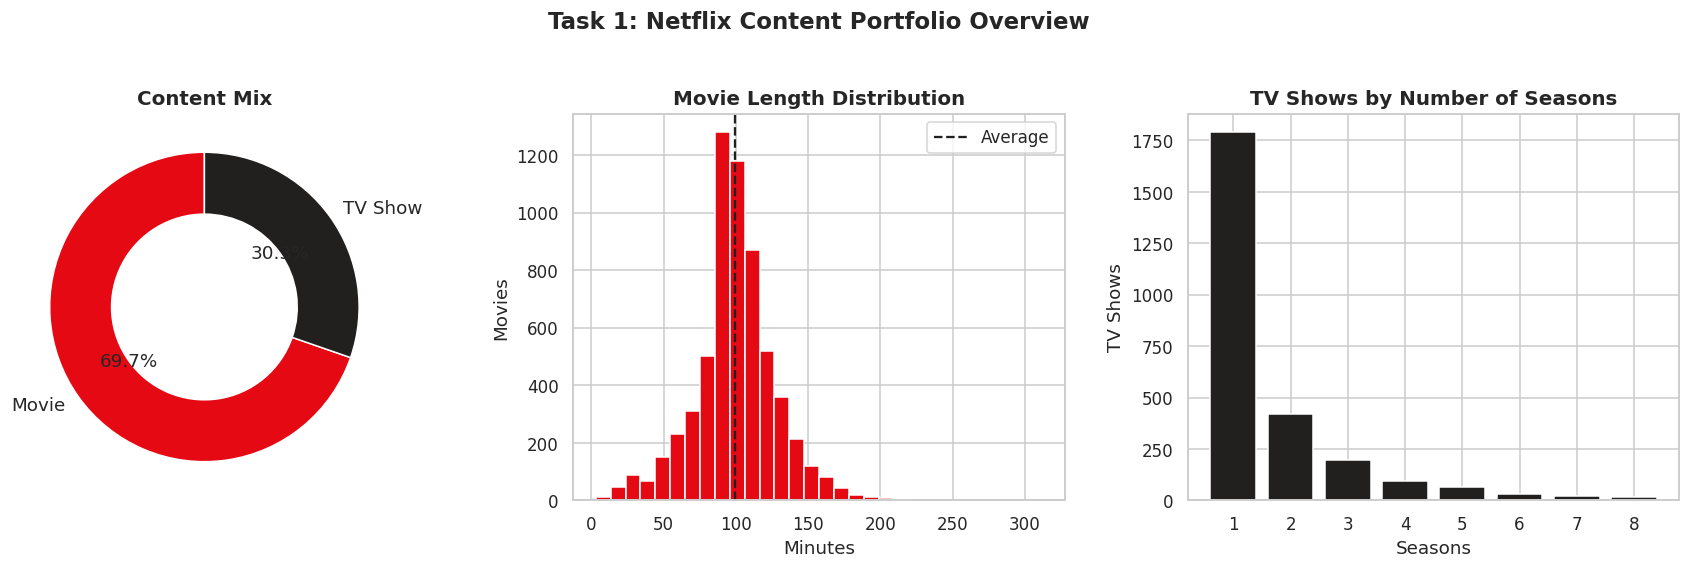

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

axes[0].pie(type_counts, labels=type_counts.index, autopct="%1.1f%%", startangle=90,
            colors=[RED, DARK], wedgeprops=dict(width=0.4, edgecolor="white"),
            textprops={"fontsize": 12})
axes[0].set_title("Content Mix")

axes[1].hist(movies["duration_num"], bins=30, color=RED, edgecolor="white")
axes[1].axvline(movies["duration_num"].mean(), color=DARK, ls="--", label="Average")
axes[1].set(title="Movie Length Distribution", xlabel="Minutes", ylabel="Movies")
axes[1].legend()

season_counts = shows["duration_num"].value_counts().sort_index()
season_counts = season_counts[season_counts.index <= 8]
axes[2].bar(season_counts.index.astype(str), season_counts.values, color=DARK)
axes[2].set(title="TV Shows by Number of Seasons", xlabel="Seasons", ylabel="TV Shows")

fig.suptitle("Task 1: Netflix Content Portfolio Overview", fontsize=15, fontweight="bold", y=1.03)
save("task1_portfolio_overview")

### Task 1: Key observations
- **Movies dominate the catalog:** 6,126 of 8,790 titles (69.7%) are movies, against 2,664 TV Shows (30.3%). That is about 2.3 movies for every TV show.
- **Movies are a standard length:** the average runtime is about 100 minutes, with most titles clustered around 80 to 120 minutes.
- **TV Shows are mostly short-run:** the average show has 1.75 seasons, and 67% have only one season. This suggests a lot of limited series or shows that were not renewed.
- **Business meaning:** the library is movie-heavy, but TV series are what keep subscribers watching week after week. Task 4 shows the TV share is rising.

---
# Task 2: Global Market Performance Analysis
**Goal:** find the major content markets using country-wise content availability.

In [16]:
known = df[df["country"] != "Unknown"].copy()
country_counts = known["country"].value_counts()

top10 = country_counts.head(10)
market = pd.DataFrame({"Titles": top10, "Share (%)": (top10 / len(known) * 100).round(1)})
market["Cumulative share (%)"] = market["Share (%)"].cumsum().round(1)
print(f"Titles with a known country: {len(known):,}  |  Countries: {country_counts.size}")
market

Titles with a known country: 8,503  |  Countries: 85


,Titles,Share (%),Cumulative share (%)
country,,,
United States,3240,38.1,38.1
India,1057,12.4,50.5
United Kingdom,638,7.5,58.0
Pakistan,421,5.0,63.0
Canada,271,3.2,66.2
Japan,259,3.0,69.2
South Korea,214,2.5,71.7
France,213,2.5,74.2
Spain,182,2.1,76.3


In [17]:
# Simple regional grouping (countries outside this list fall into 'Other')
regions = {
    "North America": ["United States", "Canada"],
    "Latin America": ["Mexico", "Brazil", "Argentina", "Colombia", "Chile", "Peru"],
    "Europe": ["United Kingdom", "France", "Spain", "Germany", "Italy", "Ireland", "Netherlands",
               "Sweden", "Belgium", "Poland", "Denmark", "Norway", "Russia", "Switzerland"],
    "Asia-Pacific": ["India", "Pakistan", "Japan", "South Korea", "China", "Hong Kong", "Taiwan",
                     "Thailand", "Indonesia", "Philippines", "Singapore", "Australia", "New Zealand",
                     "Malaysia", "Vietnam", "Bangladesh"],
    "Middle East & Africa": ["Egypt", "Nigeria", "South Africa", "Turkey", "Saudi Arabia",
                             "United Arab Emirates", "Lebanon", "Israel", "Kenya", "Morocco"],
}
country_to_region = {c: r for r, lst in regions.items() for c in lst}
known["region"] = known["country"].map(country_to_region).fillna("Other")

region_counts = known["region"].value_counts()
region_table = pd.DataFrame({"Titles": region_counts, "Share (%)": (region_counts / len(known) * 100).round(1)})
region_table

,Titles,Share (%)
region,,
North America,3511,41.3
Asia-Pacific,2643,31.1
Europe,1404,16.5
Middle East & Africa,465,5.5
Latin America,372,4.4
Other,108,1.3


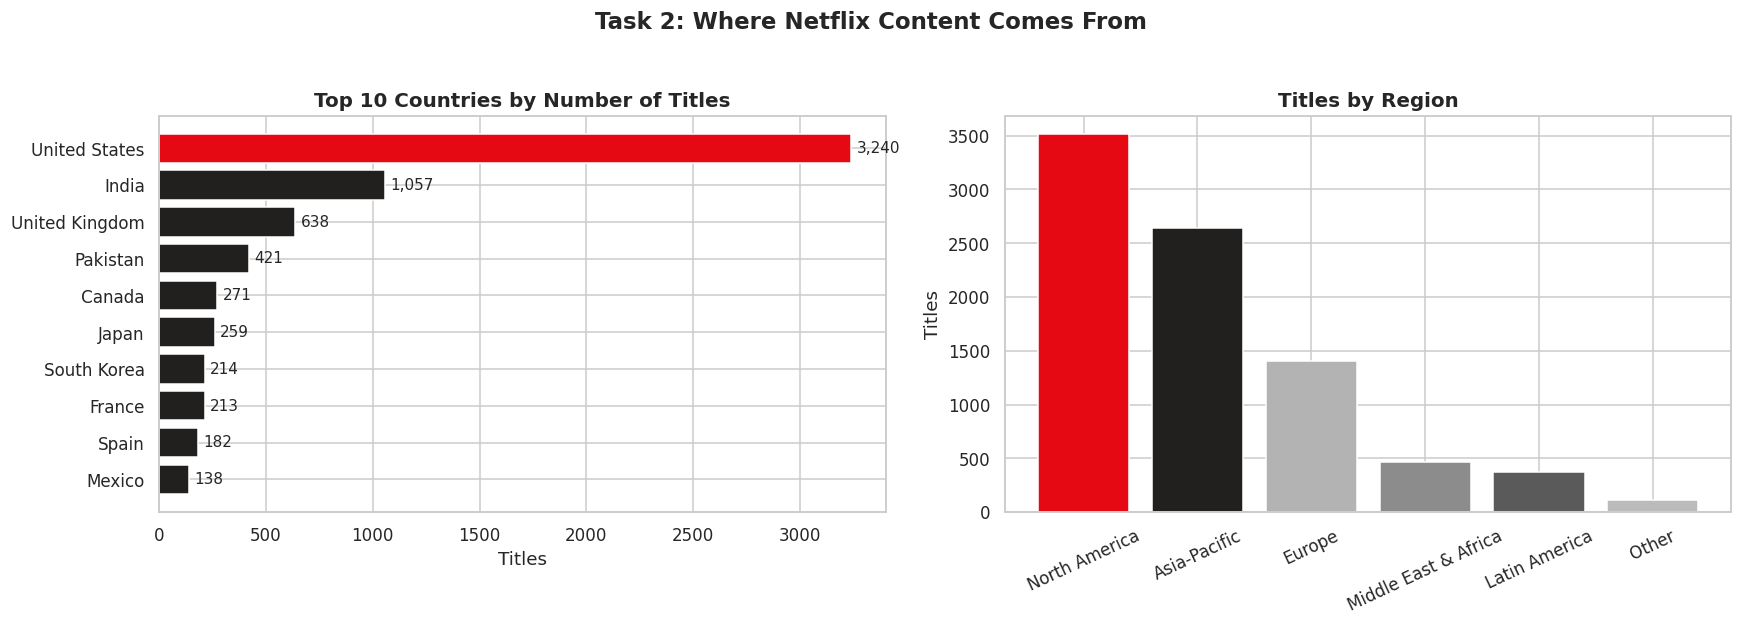

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

colors = [RED if c == "United States" else DARK for c in top10.index]
axes[0].barh(top10.index[::-1], top10.values[::-1], color=colors[::-1])
for i, v in enumerate(top10.values[::-1]):
    axes[0].text(v + 25, i, f"{v:,}", va="center", fontsize=10)
axes[0].set(title="Top 10 Countries by Number of Titles", xlabel="Titles")

axes[1].bar(region_counts.index, region_counts.values, color=[RED, DARK, GREY, "#8c8c8c", "#5a5a5a", "#bbbbbb"][:len(region_counts)])
axes[1].set(title="Titles by Region", ylabel="Titles")
axes[1].tick_params(axis="x", rotation=25)

fig.suptitle("Task 2: Where Netflix Content Comes From", fontsize=15, fontweight="bold", y=1.03)
save("task2_market_overview")

In [19]:
# Market momentum: how recent is each country's catalog, and is it TV or movie driven?
top20 = country_counts.head(20).index
momentum = (
    known[known["country"].isin(top20)]
    .groupby("country")
    .agg(Titles=("show_id", "count"),
         Recent_share_pct=("release_year", lambda s: (s >= 2018).mean() * 100),
         TV_share_pct=("type", lambda s: (s == "TV Show").mean() * 100))
    .sort_values("Titles", ascending=False)
    .round(1)
)
momentum

,Titles,Recent_share_pct,TV_share_pct
country,,,
United States,3240,40.2,26.1
India,1057,30.5,7.7
United Kingdom,638,36.4,39.3
Pakistan,421,59.4,83.1
Canada,271,42.1,31.0
Japan,259,40.5,66.4
South Korea,214,49.1,77.1
France,213,46.9,30.5
Spain,182,61.0,29.1


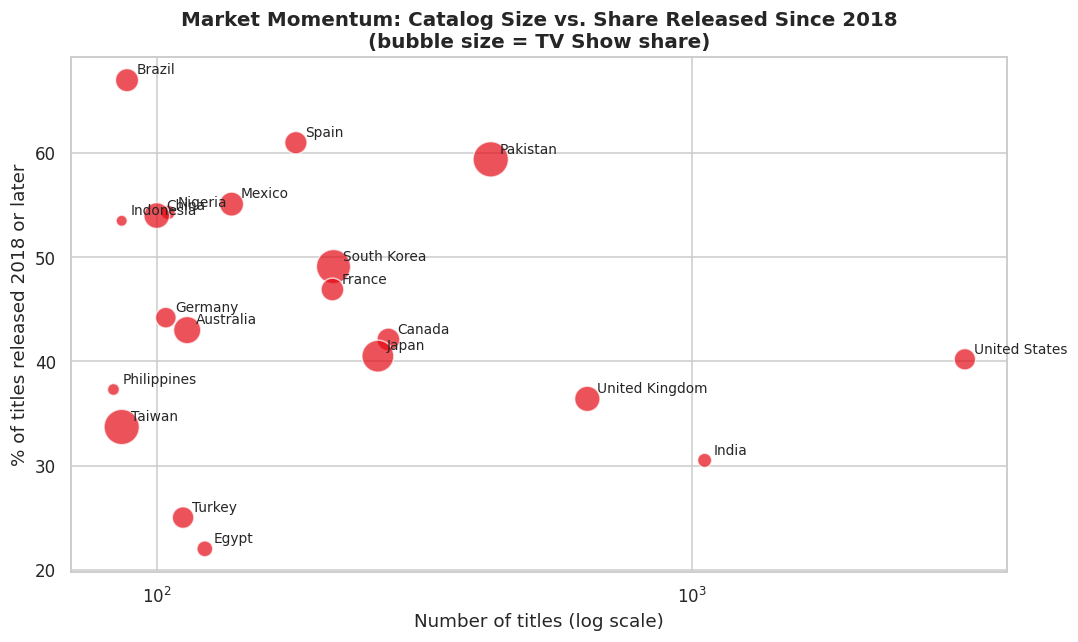

In [20]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(momentum["Titles"], momentum["Recent_share_pct"], s=momentum["TV_share_pct"] * 6 + 40,
           color=RED, alpha=0.7, edgecolor="white")
for name, row in momentum.iterrows():
    ax.annotate(name, (row["Titles"], row["Recent_share_pct"]), xytext=(6, 4), textcoords="offset points", fontsize=9)
ax.set_xscale("log")
ax.set(title="Market Momentum: Catalog Size vs. Share Released Since 2018\n(bubble size = TV Show share)",
       xlabel="Number of titles (log scale)", ylabel="% of titles released 2018 or later")
save("task2_market_momentum")

### Task 2: Key observations
- **The US is the anchor market:** 3,240 titles, or 38.1% of titles with a known country. India (1,057; 12.4%) and the UK (638; 7.5%) follow. These three countries make up 58% of the catalog.
- **Content is concentrated:** the top 5 countries account for 66% and the top 10 for 78%. Pakistan (421) is a surprising 4th, ahead of Canada, Japan and South Korea.
- **Regions:** North America (41.3%), Asia-Pacific (31.1%) and Europe (16.5%) supply about 89% of titles. Latin America (4.4%) and the Middle East & Africa (5.5%) are small, but Brazil, Mexico and Nigeria have recent, growing catalogs.
- **Momentum differs by market:** Brazil (67% of its titles released since 2018), Spain (61%), Pakistan (59%), Mexico (55%) and Nigeria (54%) have the most recent catalogs. India (30%), Egypt (22%) and Turkey (25%) lean on older content.
- **Format differs by market:** South Korea (77% TV), Japan (66%) and Pakistan (83%) are TV-led. India (8% TV) and Nigeria (9% TV) are almost entirely movie-led.

### Task 2: Expansion recommendations
1. **Build TV series in India and Nigeria.** Both have large movie catalogs but tiny TV shares, so original series would add binge-able content in high-volume markets.
2. **Invest in the fast-growing catalogs:** Brazil, Spain, Mexico and Nigeria have recent, growing libraries, which suggests rising local investment.
3. **Keep growing Korean and Japanese series,** which are strongly TV-led.
4. **Refresh older catalogs** in Egypt and Turkey, where most titles are more than three years old.

_Note: "performance" here means number of titles available, since the dataset has no viewership data._

---
# Task 3: Audience Segmentation Analysis
**Goal:** use content ratings to understand audience segments.

In [21]:
rating_map = {
    "TV-Y": "Kids", "TV-Y7": "Kids", "TV-Y7-FV": "Kids", "TV-G": "Kids", "G": "Kids",
    "TV-PG": "Teens & Family", "PG": "Teens & Family", "PG-13": "Teens & Family", "TV-14": "Teens & Family",
    "TV-MA": "Adults", "R": "Adults", "NC-17": "Adults",
    "NR": "Unrated", "UR": "Unrated",
}
order = ["Kids", "Teens & Family", "Adults", "Unrated"]
df["audience"] = df["rating"].map(rating_map)
assert df["audience"].notna().all(), "Some ratings are not mapped"

aud = df["audience"].value_counts().reindex(order)
audience_table = pd.DataFrame({"Titles": aud, "Share (%)": (aud / len(df) * 100).round(1)})
audience_table

,Titles,Share (%)
audience,,
Kids,906,10.3
Teens & Family,3795,43.2
Adults,4007,45.6
Unrated,82,0.9


In [22]:
by_type = (pd.crosstab(df["type"], df["audience"], normalize="index")[order] * 100).round(1)
by_type

audience,Kids,Teens & Family,Adults,Unrated
type,,,,
Movie,7.2,44.8,46.7,1.3
TV Show,17.4,39.5,43.0,0.2


In [23]:
rating_type = pd.crosstab(df["rating"], df["type"])
rating_type["Total"] = rating_type.sum(axis=1)
rating_type = rating_type.sort_values("Total", ascending=False)
rating_type

type,Movie,TV Show,Total
rating,,,
TV-MA,2062,1143,3205
TV-14,1427,730,2157
TV-PG,540,321,861
R,797,2,799
PG-13,490,0,490
TV-Y7,139,194,333
TV-Y,131,175,306
PG,287,0,287
TV-G,126,94,220


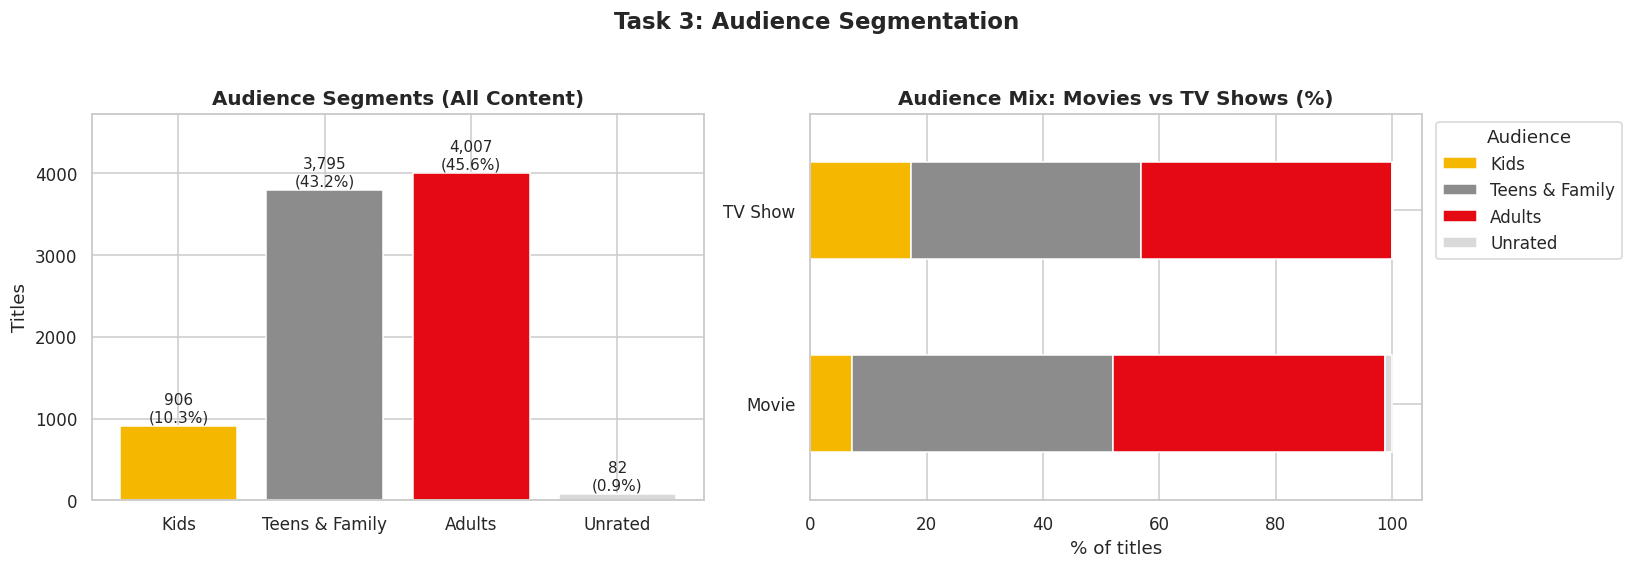

In [24]:
seg_colors = {"Kids": "#f5b700", "Teens & Family": "#8c8c8c", "Adults": RED, "Unrated": "#d9d9d9"}

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].bar(aud.index, aud.values, color=[seg_colors[s] for s in aud.index])
for i, v in enumerate(aud.values):
    axes[0].text(i, v + 50, f"{v:,}\n({v/len(df):.1%})", ha="center", fontsize=10)
axes[0].set(title="Audience Segments (All Content)", ylabel="Titles", ylim=(0, aud.max() * 1.18))

by_type.plot(kind="barh", stacked=True, ax=axes[1], color=[seg_colors[c] for c in by_type.columns])
axes[1].set(title="Audience Mix: Movies vs TV Shows (%)", xlabel="% of titles", ylabel="")
axes[1].legend(title="Audience", bbox_to_anchor=(1.01, 1), loc="upper left")

fig.suptitle("Task 3: Audience Segmentation", fontsize=15, fontweight="bold", y=1.03)
save("task3_audience_segments")

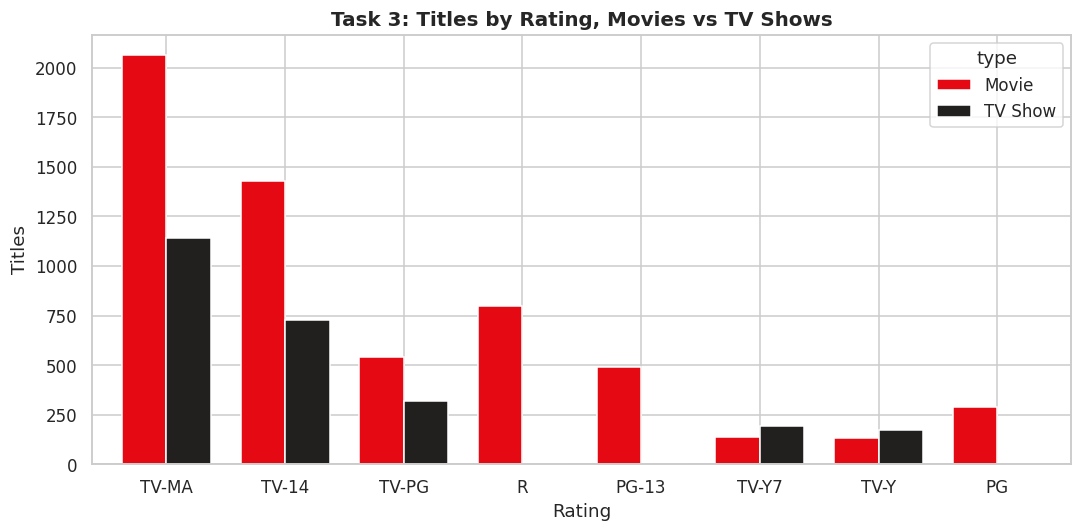

In [25]:
top_ratings = rating_type.head(8).drop(columns="Total")
ax = top_ratings.plot(kind="bar", figsize=(10, 5), color=[RED, DARK], width=0.75)
ax.set(title="Task 3: Titles by Rating, Movies vs TV Shows", xlabel="Rating", ylabel="Titles")
plt.xticks(rotation=0)
save("task3_rating_by_type")

### Task 3: Key observations
- **Adults are the largest segment:** 45.6% of titles, just ahead of Teens & Family (43.2%). Kids content is only 10.3%, and unrated content is under 1%.
- **Two ratings carry the catalog:** TV-MA (3,205 titles, 36.5%) and TV-14 (2,157 titles, 24.5%) together make up 61% of everything.
- **Movies vs TV Shows:** movies skew slightly more adult (46.7% vs 43.0%), but **TV is much stronger in Kids content** (17.4% of TV Shows vs 7.2% of movies).
- **The movie kids gap:** only 7.2% of movies target children, and only 41 are rated G.

### Task 3: Audience-focused recommendations
1. **Add kids and family movies.** At 7.2% of movies, this is the thinnest segment, and family content brings parents and children onto the same account.
2. **Keep investing in mature drama and thriller series** (TV-MA / TV-14) while balancing the mix, since this is the core audience.
3. **Grow kids TV** (TV-Y, TV-Y7). It is already the strongest kids format and supports repeat viewing.
4. **Improve rating metadata** for the small unrated group so profiles and parental controls work properly.

---
# Task 4: Content Growth & Trend Analysis
**Goal:** analyze release trends to evaluate Netflix's growth strategy.

In [26]:
by_year = df.groupby(["release_year", "type"]).size().unstack(fill_value=0)
by_year["Total"] = by_year.sum(axis=1)
by_year["TV share (%)"] = (by_year["TV Show"] / by_year["Total"] * 100).round(1)
by_year["YoY growth (%)"] = (by_year["Total"].pct_change() * 100).round(1)
by_year.loc[2008:2021]

type,Movie,TV Show,Total,TV share (%),YoY growth (%)
release_year,,,,,
2008,113,22,135,16.3,53.4
2009,118,34,152,22.4,12.6
2010,153,39,192,20.3,26.3
2011,145,40,185,21.6,-3.6
2012,173,63,236,26.7,27.6
2013,225,61,286,21.3,21.2
2014,264,88,352,25.0,23.1
2015,396,159,555,28.6,57.7
2016,658,243,901,27.0,62.3


In [27]:
added = df.groupby(["year_added", "type"]).size().unstack(fill_value=0)
added["Total"] = added.sum(axis=1)
added["YoY growth (%)"] = (added["Total"].pct_change() * 100).round(1)
added.loc[2014:2021]

type,Movie,TV Show,Total,YoY growth (%)
year_added,,,,
2014,19,5,24,118.2
2015,56,26,82,241.7
2016,251,175,426,419.5
2017,836,349,1185,178.2
2018,1237,411,1648,39.1
2019,1424,592,2016,22.3
2020,1284,595,1879,-6.8
2021,993,505,1498,-20.3


In [28]:
peak_year = by_year["Total"].idxmax()
cagr = (by_year.loc[2018, "Total"] / by_year.loc[2010, "Total"]) ** (1 / 8) - 1
print(f"Peak release year: {peak_year} ({by_year.loc[peak_year, 'Total']:,} titles)")
print(f"Titles released 2010 -> 2018: {by_year.loc[2010, 'Total']} -> {by_year.loc[2018, 'Total']} (CAGR {cagr:.1%})")
print(f"Share of catalog released since 2015: {(df['release_year'] >= 2015).mean():.1%}")
print(f"Share of catalog released before 2000: {(df['release_year'] < 2000).mean():.1%}")

Peak release year: 2018 (1,146 titles)
Titles released 2010 -> 2018: 192 -> 1146 (CAGR 25.0%)
Share of catalog released since 2015: 70.6%
Share of catalog released before 2000: 6.0%


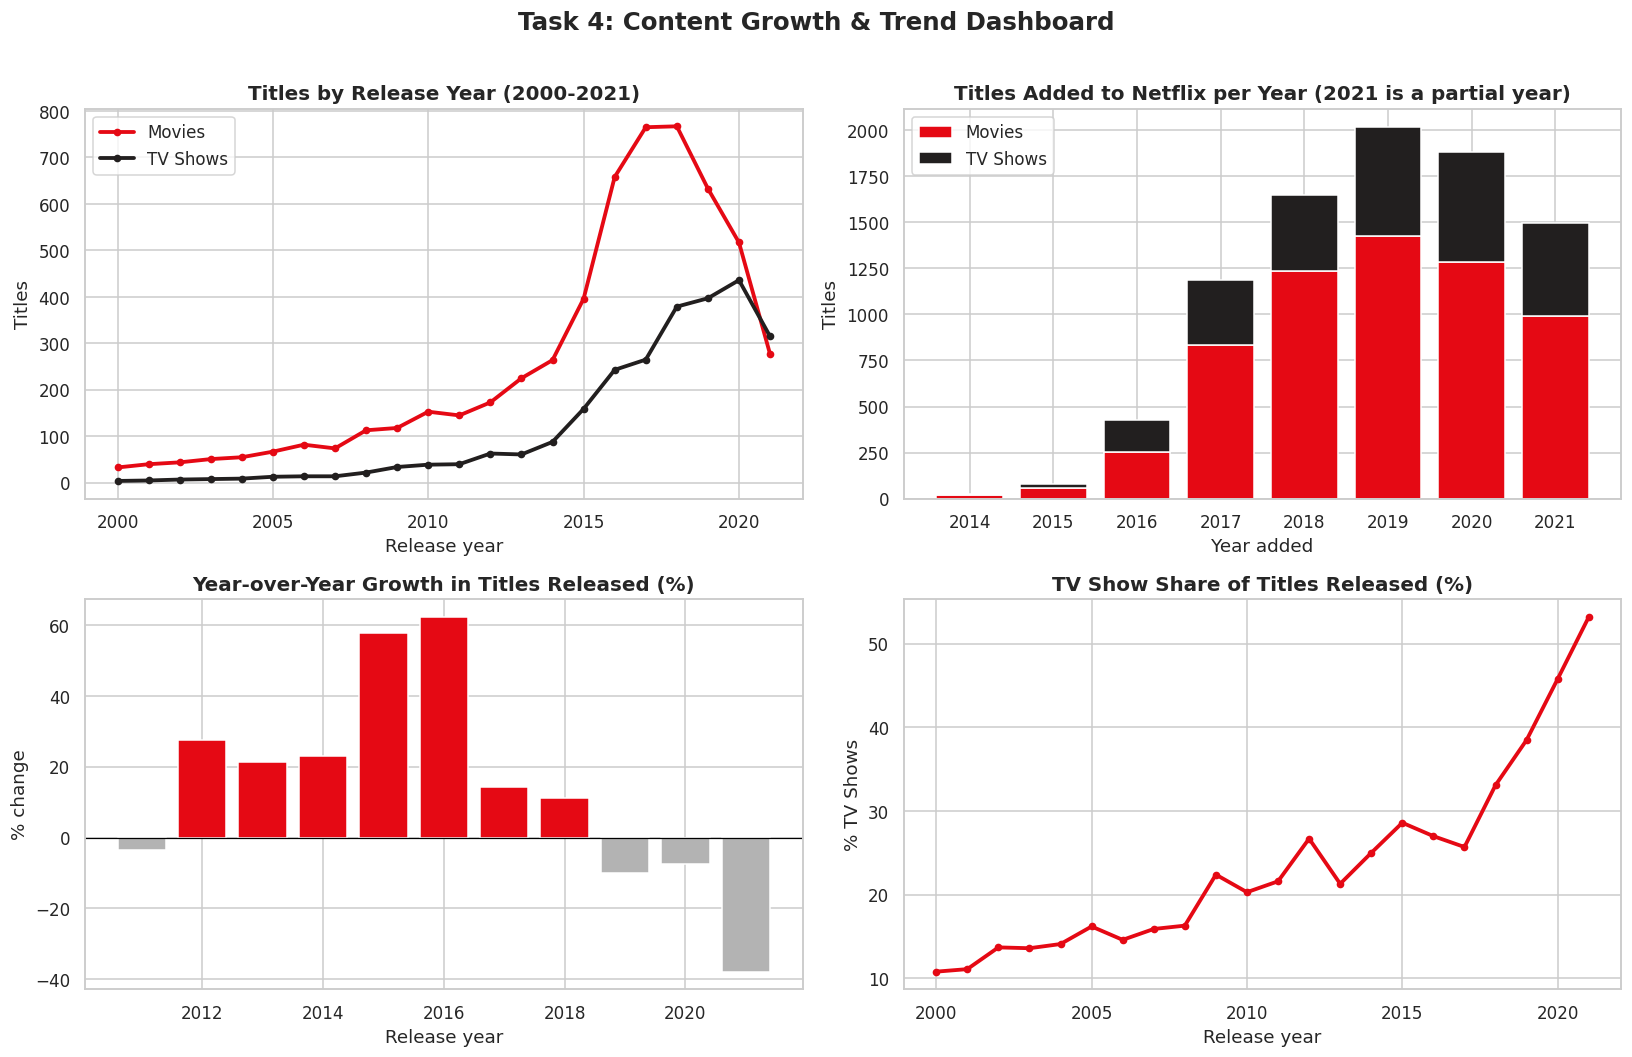

In [29]:
yrs = by_year.loc[2000:2021]
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

axes[0, 0].plot(yrs.index, yrs["Movie"], color=RED, lw=2.5, marker="o", ms=4, label="Movies")
axes[0, 0].plot(yrs.index, yrs["TV Show"], color=DARK, lw=2.5, marker="o", ms=4, label="TV Shows")
axes[0, 0].set(title="Titles by Release Year (2000-2021)", xlabel="Release year", ylabel="Titles")
axes[0, 0].legend()

a = added.loc[2014:2021]
axes[0, 1].bar(a.index, a["Movie"], color=RED, label="Movies")
axes[0, 1].bar(a.index, a["TV Show"], bottom=a["Movie"], color=DARK, label="TV Shows")
axes[0, 1].set(title="Titles Added to Netflix per Year (2021 is a partial year)", xlabel="Year added", ylabel="Titles")
axes[0, 1].legend()

g = by_year.loc[2011:2021, "YoY growth (%)"]
axes[1, 0].bar(g.index, g.values, color=[RED if v >= 0 else GREY for v in g.values])
axes[1, 0].axhline(0, color="black", lw=0.8)
axes[1, 0].set(title="Year-over-Year Growth in Titles Released (%)", xlabel="Release year", ylabel="% change")

axes[1, 1].plot(yrs.index, yrs["TV share (%)"], color=RED, lw=2.5, marker="o", ms=4)
axes[1, 1].set(title="TV Show Share of Titles Released (%)", xlabel="Release year", ylabel="% TV Shows")

fig.suptitle("Task 4: Content Growth & Trend Dashboard", fontsize=16, fontweight="bold", y=1.01)
save("task4_growth_dashboard")

### Task 4: Key observations
- **Rapid expansion in the 2010s:** titles released per year grew from 192 in 2010 to a peak of 1,146 in 2018, a compound growth of roughly 25% a year. About 71% of the catalog was released in 2015 or later.
- **The big growth years:** release counts jumped 58% in 2015 and 62% in 2016. Growth then slowed (+14% in 2017, +11% in 2018).
- **Titles added to the platform surged from 2016:** 82 titles were added in 2015, 426 in 2016 and 2,016 in 2019 (the peak), then 1,879 in 2020 and 1,498 in 2021 (partial year).
- **The mix is shifting toward TV:** TV Shows were 20% of titles released in 2010 and reach 53% for 2021. Movies peaked at 767 titles in 2018 and fell to 277 in 2021, while TV grew to 436 in 2020.
- **Caution on the decline after 2018:** the drop in 2019 to 2021 partly reflects the data cut-off (2021 is incomplete) and titles that had not yet been added, so it should not be read as a collapse.

### Task 4: Strategic insights
1. **Netflix grew by volume in the 2010s and is now shifting toward TV series.** The share of TV rose every year since 2017.
2. **Catalog depth is mostly recent.** Only about 6% of titles were released before 2000, so the library relies on new content rather than classics.
3. **Planning implication:** with additions flattening after 2019, the next stage of growth likely comes from the quality and regional mix of content, not just volume.

---
# Conclusion
Netflix's catalog is movie-heavy but moving toward TV, concentrated in a few countries (US, India, UK), skewed toward adult and teen audiences, and built mostly in the last decade. The clearest opportunities are TV series in movie-led markets (India, Nigeria), kids and family movies, and continued growth in fast-rising regional markets (Brazil, Spain, Mexico).